In [14]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [15]:
# Load the data using your exact verified path
df = pd.read_csv('/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Verify the shape
print('Dataset shape:', df.shape)
df.head()


Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Dataset Overview


In [16]:
# A. General Data Breakdown
print("=== Column Information ===")
df.info()

# B. Convert TotalCharges from text to numbers
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"\nMissing values in TotalCharges after numerical fix: {df['TotalCharges'].isnull().sum()}")

# C. Look at how many people are leaving (Target Variable)
print("\n=== Churn Distribution ===")
print(df['Churn'].value_counts())
print("\n=== Churn Percentage ===")
print(df['Churn'].value_counts(normalize=True) * 100)


=== Column Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBillin

### Key Insights from Numerical Features:
* **Tenure Impact:** Customers who churn (leave) have a significantly shorter median tenure (often under 10 months) compared to loyal customers.
* **Charges Impact:** Customers who churn tend to have higher monthly charges, showing a higher median bill concentrated around $80-$90. High bills are a primary churn indicator.


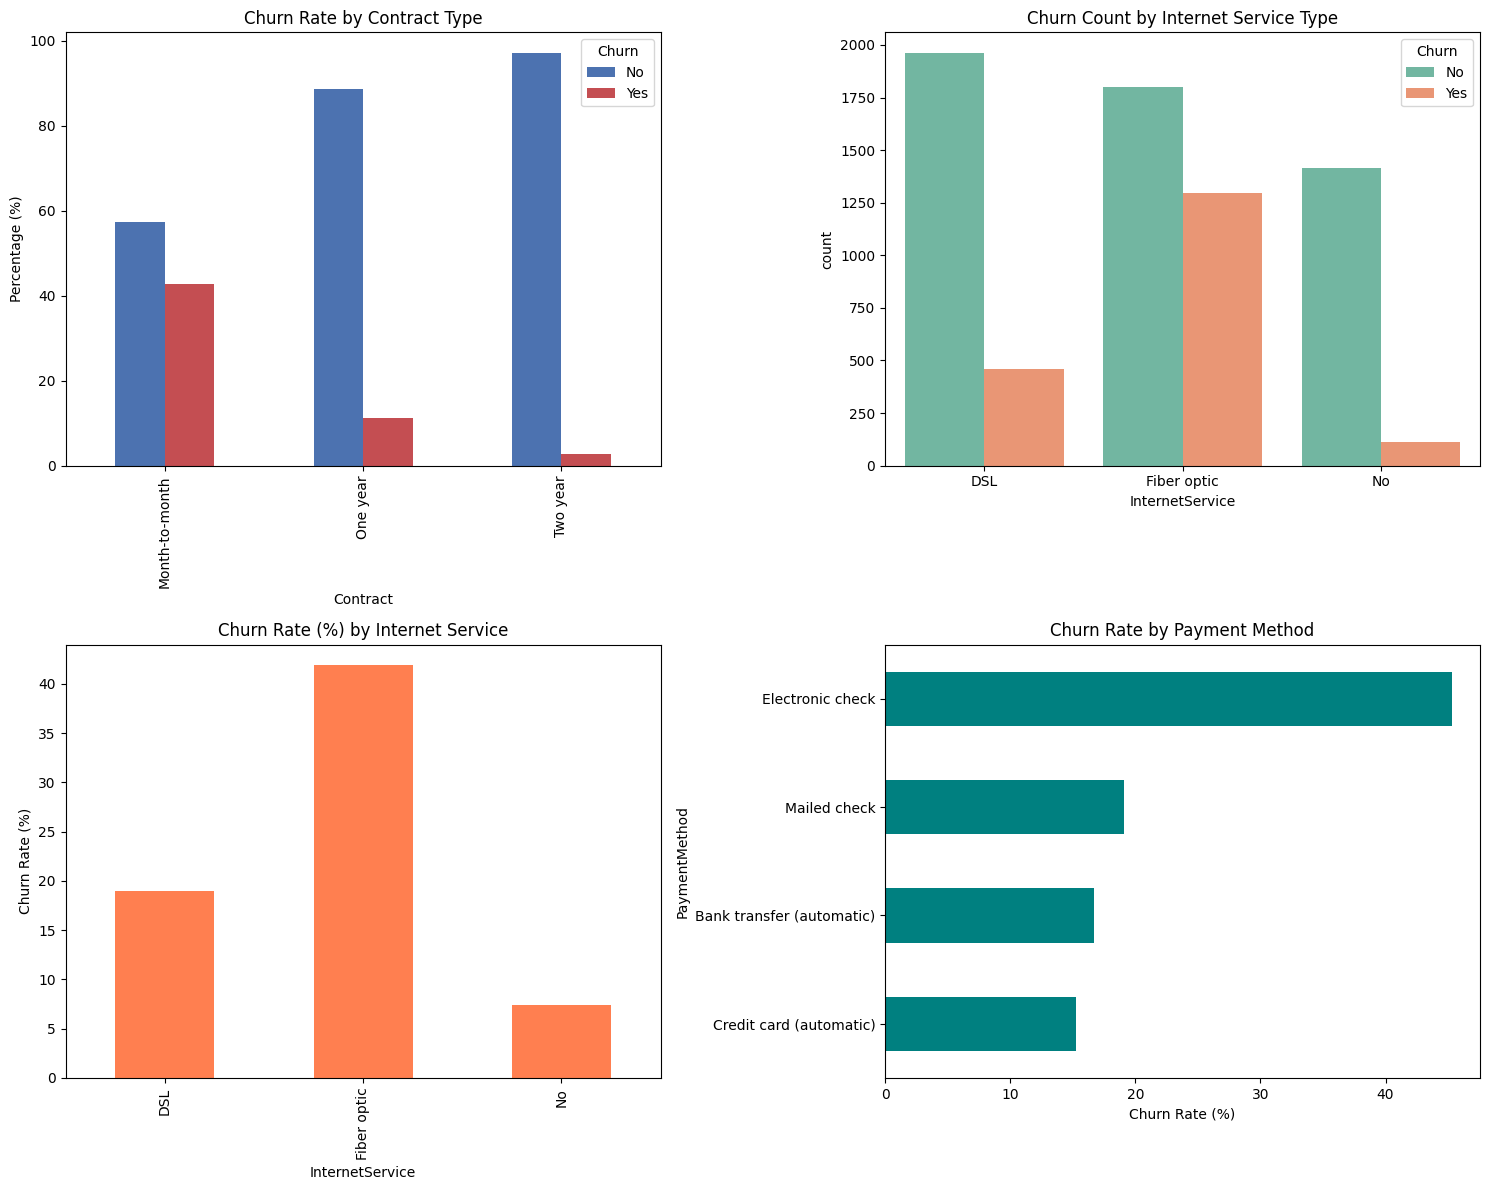

In [18]:
# Force-import the missing plotting libraries right here
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set up a large plotting window for our categorical insights
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Plot 4: Churn Rate by Contract Type
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn.plot(kind='bar', stacked=False, ax=axes[0,0], color=['#4c72b0', '#c44e52'])
axes[0,0].set_title('Churn Rate by Contract Type')
axes[0,0].set_ylabel('Percentage (%)')

# Plot 5: Churn Count by Internet Service Type
sns.countplot(x='InternetService', hue='Churn', data=df, palette='Set2', ax=axes[0,1])
axes[0,1].set_title('Churn Count by Internet Service Type')

# Plot 6: Churn Rate (%) by Internet Service
internet_churn = pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100
internet_churn['Yes'].plot(kind='bar', color='coral', ax=axes[1,0])
axes[1,0].set_title('Churn Rate (%) by Internet Service')
axes[1,0].set_ylabel('Churn Rate (%)')

# Plot 7: Churn Rate by Payment Method
payment_churn = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index') * 100
payment_churn['Yes'].sort_values().plot(kind='barh', color='teal', ax=axes[1,1])
axes[1,1].set_title('Churn Rate by Payment Method')
axes[1,1].set_xlabel('Churn Rate (%)')

plt.tight_layout()
plt.show()


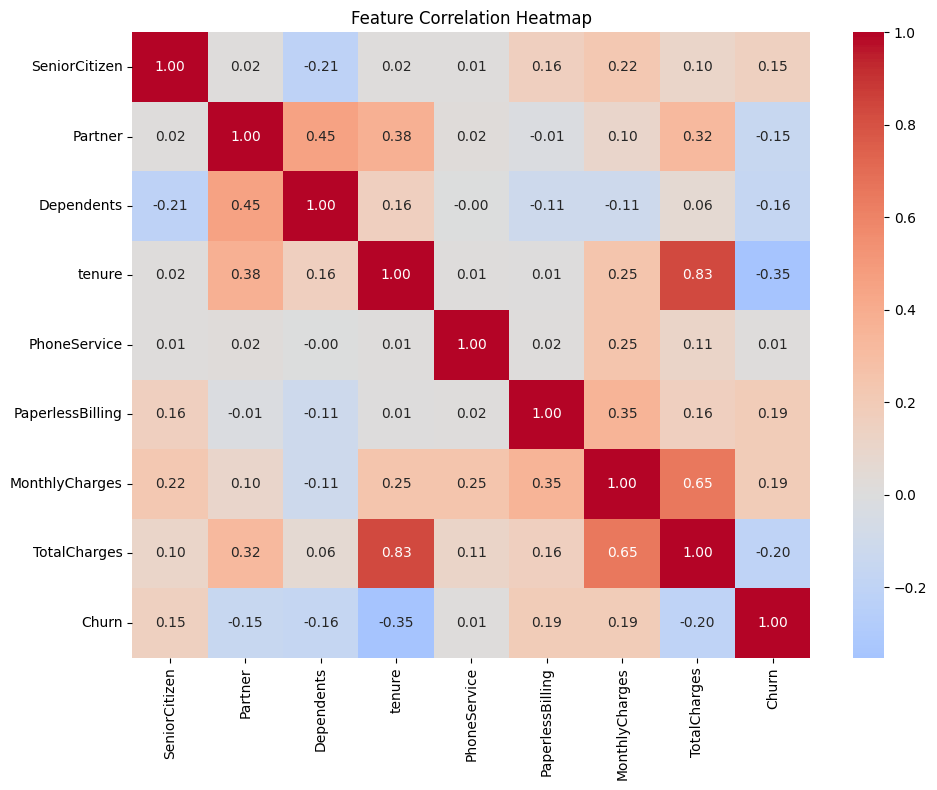

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Prepare numeric data for correlation mapping
df_numeric = df.copy()
binary_cols = ['Churn', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']

for col in binary_cols:
    if col in df_numeric.columns:
        df_numeric[col] = df_numeric[col].map({'Yes': 1, 'No': 0})

numeric_features = df_numeric.select_dtypes(include=[np.number])

# Generate the heatmap matrix
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_features.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


### Key Insights from Correlation Analysis:
* **Tenure vs. Churn:** A clear negative correlation exists between tenure and churn, verifying that long-term customers are far less likely to leave the company.
* **Charges Relationship:** Total charges are heavily correlated with tenure. This confirms that long-standing accounts naturally accumulate much higher billing totals over time.

